# **Classification with Scikit-learn using the Iris Dataset**

## **What is Classification?**

Classification is one of the two fundamental approaches in supervised machine learning : the other being regression. Where regression predicts a continuous number (like a house price), classification predicts a **discrete category** - a label chosen from a fixed set of possibilities.

Think of it like a multiple-choice test for a computer. The answer options are always the same predefined categories; only the question (the input data) changes each time. An object classifier, for example, always picks from the same list of objects : it just looks at a different input each time.

The function or program that performs this assignment is called a **classifier**. It takes a data point as input and outputs a **label** - the name of the class it belongs to.

> A spam filter is a classifier. Every email is a data point. The classes are simple: *Spam* or *Not Spam*. The classifier reads the email and decides which bucket it belongs to.

A classifier **learns** by studying labeled examples - data points where the correct answer is already known. It finds patterns in the input features that reliably separate the classes. Once trained, it applies those learned patterns to new, unseen data.

The key constraint that makes classification different from regression: **the output is always one of a small, fixed set of discrete values.**
![Classification boundary illustration](https://cdn.botpenguin.com/assets/website/Classification_Algorithm_f6b45f3f99.png)

[Image Source](https://botpenguin.com/glossary/classification-algorithm)

## **Scikit-learn**

[Scikit-learn](https://scikit-learn.org) is a free, open-source machine learning library for Python.


The library covers the full ML workflow in one place - classification, regression, clustering, preprocessing, model selection, and evaluation. What makes it stand out is its **consistent API**: every model follows the same pattern - `fit()` to train, `predict()` to infer - so switching between algorithms requires almost no code changes.

For this notebook, three components are central:

- `Pipeline` : chains multiple processing steps into a single object that behaves like one model. Instead of manually scaling data, then training, then remembering to scale again at inference - the Pipeline does it all in order, automatically.

- `StandardScaler` : transforms each feature so it has a **mean of 0 and standard deviation of 1**. Without this, features measured in large units (like sepal length in cm) would dominate features in smaller units, throwing off distance-based algorithms like SVM. Scaling puts every feature on equal footing before the model sees the data.

- `SVC` (Support Vector Classifier) : finds the **optimal hyperplane (think of a line)** that separates classes with the maximum possible margin between them. It works by identifying the data points closest to the boundary - called **support vectors** - and maximizing the gap around them. Like shown in the image above.


## **The Iris Dataset**

The Iris dataset, contains **150 flower samples** across 3 species: *setosa*, *versicolor*, and *virginica*.
Each sample has 4 numerical measurements: sepal length, sepal width, petal length, and petal width (all in cm).
It ships built-in with scikit-learn and is the go-to dataset for learning classification - clean, balanced, and zero preprocessing needed.



## **Installing Dependencies**
Installing the dependencies that will be requred throught this notebook

Each package plays a specific role:

- `scikit-learn` : ML algorithms, preprocessing, evaluation metrics
- `pandas` : tabular data manipulation and DataFrame support
- `matplotlib` : base plotting library used by seaborn and scikit-learn
- `seaborn` : statistical visualization built on matplotlib, cleaner defaults



In [1]:
!pip install scikit-learn pandas matplotlib seaborn

Looking in indexes: https://pypi.org/simple, https://pypi.ngc.nvidia.com


## **Load the Dataset**

`load_iris()` returns a sklearn `Bunch` object : a dict-like container.

- `iris.data` - feature matrix `X`, shape `(150, 4)`
- `iris.target` - label array `y`, integers `0 / 1 / 2`
- `iris.feature_names` - list of 4 feature name strings
- `iris.target_names` - `['setosa', 'versicolor', 'virginica']`

`X.shape` confirms 150 samples × 4 features. `y.shape` confirms 150 labels.

### **Understanding the Iris Dataset**

The **Iris dataset** is one of the most famous and beginner-friendly datasets used in Machine Learning. It is mainly used for learning and practicing classification problems. The dataset contains information about iris flowers, where a Machine Learning model learns flower patterns from measurements and predicts the correct flower species.

The dataset contains **150 flower samples** divided into **3 different iris species**:

* Iris Setosa
* Iris Versicolor
* Iris Virginica

Each flower sample includes **4 important measurements (features)**:

* Sepal Length
* Sepal Width
* Petal Length
* Petal Width

These measurements are used as input data for training Machine Learning models.


### **Features and Target in the Iris Dataset**

#### **Features (`X`)**

Features are the input values given to the model.

In the Iris dataset, the features are the flower measurements:

* Sepal length
* Sepal width
* Petal length
* Petal width

The model studies these values to learn patterns between different flower species.


#### **Target (`Y`)**

The target represents the output label that the model needs to predict.

In this dataset, the target corresponds to the flower species:

* `0` → Setosa
* `1` → Versicolor
* `2` → Virginica

The main goal is to predict the correct flower species based on the given measurements.

### **Dataset Shape**

* `X.shape = (150, 4)`

  * 150 flower samples
  * 4 features for each sample

* `y.shape = (150,)`

  * 150 target labels

In [1]:
from sklearn.datasets import load_iris

iris = load_iris()

X = iris.data
y = iris.target

feature_names = iris.feature_names
target_names = iris.target_names

print("Feature names:", feature_names)
print("Target names:", target_names)
print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target names: ['setosa' 'versicolor' 'virginica']
Shape of X: (150, 4)
Shape of y: (150,)


## 📋 **Convert to Pandas DataFrame**
Raw sklearn data = **numpy arrays** - just numbers, no column names, no context. Useless for humans. DataFrame wraps it into labeled, readable table.


**`pd.DataFrame(X, columns=feature_names)`** : assigns column names to raw array. Index 0,1,2,3 becomes `sepal length (cm)`, `petal width (cm)` etc.

**`[target_names[label] for label in y]`** : `y` is integers `[0,1,2]`. Maps each : readable species name `[setosa, versicolor, virginica]`

**`df.head()`** : preview first 5 rows. Quick sanity check - columns correct, values reasonable.


## 🤔 **Why DataFrame?**

pandas DataFrames plug directly into visualization libraries like `matplotlib`, `seaborn`, `plotly`. Filter by column name, group by species, plot distributions - all in one line. Numpy arrays can't do that cleanly.

> Numbers > labeled table > ready for analysis and visualization. ✅

In [2]:
import pandas as pd

df = pd.DataFrame(X, columns=feature_names)
df["species"] = [target_names[label] for label in y]

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


##  **Dataset Visualization**

`value_counts()` counts samples per species. `.plot(kind="bar")` renders it as a bar chart.
This confirms class balance - 50 samples per species, no imbalance to worry about.



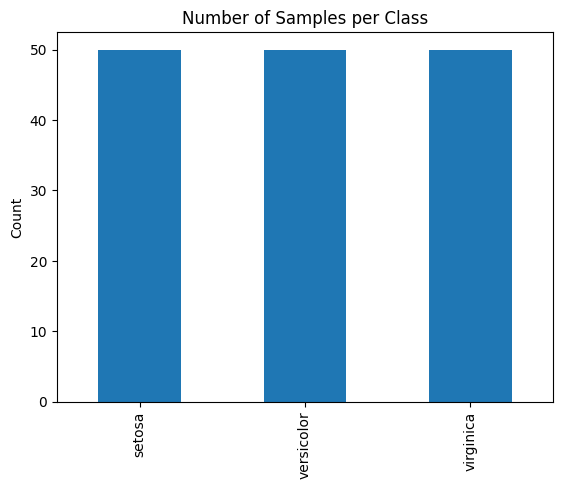

In [4]:
import matplotlib.pyplot as plt
df["species"].value_counts().plot(kind="bar")
plt.title("Number of Samples per Class")
plt.ylabel("Count")
plt.show()

## 🧠 **What is Training?**
Teaching model to recognize patterns by showing it examples.

**The process:**
1. Feed data into model
2. Model makes prediction
3. Compare prediction to real answer then calculate **error**
4. Adjust model's internal parameters to reduce error
5. Repeat thousands/millions of times

> **Analogy:** 📚 Student doing practice problems. Wrong answer -> learn from mistake -> improve. Do enough problems -> start recognizing patterns.

Model's "knowledge" lives in its **parameters** - numbers that get tuned during training. After training, parameters are frozen. Model applies what it learned to new inputs.

**Key idea:** Model never memorizes answers. It learns *patterns* that generalize.


## 🔪 **What is Data Splitting?**
Slicing the full dataset into separate parts - typically **train** and **test** sets.
> Also exists as 3-way split: **Train / Validation / Test** - validation used mid-training to tune the model.

## 🤔 **Why Split?**
Two reasons.

**1. Need unseen data to measure performance**
If trains the model on everything then nothing left to test it with. 
No test set means no way to know if model actually learned anything.

**2. Model must not see test data during training**
If it does then the model memorizes answers instead of learning patterns.
Evaluation becomes meaningless and it will be like grading homework you already handed out.

> **Analogy:** 📖 Exam questions must be *different* from practice problems.
> Same questions - student memorizes, not understands. Score 100%, learned nothing.
> Different questions - score reflects true understanding.


Results now **mean something** - model performing well on unseen data = will perform similarly on real world data. 🌍

## 📊 **Split Ratio**
| Split | Ratio |
|---|---|
| 🏋️ Train | 70–80% |
| 🧪 Test | 20–30% |

Train gets the bigger share because **model needs enough data to learn from.** Show it only A, B, C , the model can't recognize X, Y, Z. Train set must be large enough and **balanced** - all classes equally represented.

Split is done randomly - but `random_state=42` **fixes the randomness.** Same split every run which makes reproducible results.

Random splitting does not guarantee even class distribution. One class might dominate train set, barely appear in test or biased make untrustworthy results.

**`stratify=y`** fixes this - splits *within each class separately*, preserving original class proportions in both train and test sets.

`y` = label column : sklearn reads class distribution from it and maintains same ratio across both splits.

> Without **`stratify=y`** : random imbalance makes evaluation wrong.  
> With **`stratify=y`** : proportional representation makes trustworthy results. ✅

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
        stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 120
Testing samples: 30


## ⚙️ **Create the Classifier**

`Pipeline` bundles two steps that always run together - scaling then classifying.

📏 **Step 1 - `StandardScaler`**

Features have different scales - sepal length ranges 4–8cm, petal width ranges 0.1–2.5cm. To SVM, larger numbers *look* more important. That's wrong - scale shouldn't mean importance.

StandardScaler fixes this - transforms every feature to same scale:
- **Mean = 0** - centers data around zero
- **Std = 1** - spreads data equally

**Analogy:** 📏 Comparing heights and weights. One person is 180cm, 75kg. Another is 160cm, 80kg. Raw numbers make height dominate just because the number is bigger. Standardizing puts both on equal footing.

$$z = \frac{x - \mu}{\sigma}$$

Every feature now lives on same scale - SVM treats all equally. **Mandatory for SVM.**



🧠 **Step 2 - `SVC`**

SVM draws **decision boundaries** - lines/curves that separate classes. New sample lands in a region and  gets that region's label.

 **`kernel="rbf"`** - Radial Basis Function
Classes aren't always linearly separable that is can't draw a straight line between them. RBF warps the feature space so curved, complex boundaries become possible.

**Analogy:** 🫧 Imagine two groups of dots mixed together on paper. Can't separate with straight line. RBF is like lifting dots into 3D space where a flat plane can now separate them cleanly.

![SVM](https://blogger.googleusercontent.com/img/b/R29vZ2xl/AVvXsEidwnlkQ36EMMfIwJl_cRpfwmQDYIQ2MzAxAU5qfSld_UzE6-zGVN7pRO8X_d3SrjW9IrzZIJwjcsC57C1y7KezJzADzPptxvgVJFXTYnnRi5ZzK2SWQrPbnk-UH4XEZVo8V80JW4gYV9RMAHfvK8AWfl5KtLutQxYKg3R9-MlvG_hqXVJJYmXWGqusNw/w507-h247-rw/svm_kernels%20intro%20(1).png)

[Image Source](https://www.quarkml.com/2022/10/the-rbf-kernel-in-svm-complete-guide.html)

**`C=1.0`** - Regularization
Controls strictness of boundary.
- **High C** means strict, fits training data tightly, risk of overfitting
- **Low C** mean lenient, allows some misclassification, more generalized

**`gamma="scale"`** - Kernel Reach
Controls how far each training point's influence reaches.
- **High gamma** : each point influences only nearby area , complex boundary
- **Low gamma** : each point influences wider area , smoother boundary
- **`"scale"`** : sklearn calculates optimal value automatically from feature variance



## 🔒 **Why `Pipeline`?**

Scaler must **only** learn from training data. If it sees test data or test statistics leak into training, the model cheats that is it memorizes that input and on  evaluation instead of predicting it remembers.

Pipeline enforces this automatically - scaler fits on train only, transforms test separately. No leakage. ✅

In [1]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

model = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", SVC(kernel="rbf", C=1.0, gamma="scale"))
])

model

Pipeline(steps=[('scaler', StandardScaler()), ('classifier', SVC())])

## **🏋️ Train the Model**

`model.fit(X_train, y_train)` trains the full pipeline - scales the features, then fits the classifier.


## **⚙️ What Actually Happens During Training?**

Model sees each sample in `X_train` alongside its true label in `y_train`. It makes a prediction then compares against true label thne measures how wrong it was (**loss**). Then adjusts internal **parameters** to reduce that error.

This repeats across all samples, many times - each pass the model gets slightly better at separating classes.

For classification specifically : model learns **decision boundaries** - invisible lines/regions in feature space that separate one class from another. By end of training, each region maps to a class label.

> Training = iteratively reducing error until model's decision boundaries best separate all classes in `X_train`. Parameters get locked. Model ready to predict. 🎯

In [12]:
model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()), ('classifier', SVC())])

## 💾 **Saving the Model**

Training is expensive - data preprocessing, learning decision boundaries, tuning parameters (this training was short because the dataset was small and task was comparitively straight, model training can takes hours and days too!). Without saving, model vanishes when script ends. Every run = retrain from scratch. Wasteful.
That is why we save the trained model, so that it can be used anytime without training it again.



### 🤔 **Why `joblib` Over `pickle`?**

Python has a built-in serialization tool called `pickle` - converts any Python object to bytes and saves to disk. Works fine for simple objects like strings, lists, dictionaries.

But ML models are different. They contain **large numpy arrays, matrices, fitted parameters** - sometimes hundreds of megabytes. `pickle` handles these poorly - slow, memory inefficient.

`joblib` was built specifically for this. Under the hood it uses **memory-mapped files** - instead of loading entire model into RAM at once, it reads only the parts needed. Faster save, faster load, lower memory usage.

> `pickle` = general purpose. `joblib` = built for numpy-heavy ML objects. Same idea, right tool for the job. ✅



### 🤔 **Why Not `model.save()` or Other Formats?**

sklearn has **no built-in `save()` method** - unlike Keras/TensorFlow (`model.save()`) or PyTorch (`torch.save()`). Those frameworks have dedicated save formats (`.h5`, `.pt`) built into the library itself.

sklearn models are just **plain Python objects** - Pipeline, SVC, StandardScaler are all Python classes with attributes. No special format exists for them. So saving = serializing the Python object itself → `joblib` or `pickle` is the natural solution.

> Other frameworks own the full training stack so they can define custom save formats.
> sklearn is just Python objects os we serialize the object into `.pkl` which is the standard. ✅

**`import joblib`**

Imports the serialization library.

**`joblib.dump(model, "iris_classifier.pkl")`**

- **`joblib.dump()`** : **serializes** the model - converts entire Python object (pipeline + learned parameters + weights) into binary format and writes to disk
- **`model`** : the trained pipeline being saved
- **`"iris_classifier.pkl"`** : output filename


### 📦 **`.pkl` Extension**

`.pkl` = **Pickle format** - Python's native binary serialization format. Stores any Python object as bytes. Not human-readable - binary file. Load it back and get exact same trained model object, ready to predict instantly.


In [14]:
import joblib

joblib.dump(model, "iris_classifier.pkl")

['iris_classifier.pkl']

## **Evaluate the Model**

## 📊 **Accuracy**


**`saved_model = joblib.load("iris_classifier.pkl")`**

Loads model from disk - parameters intact, no retraining.


**`y_pred = saved_model.predict(X_test)`**

Model predicts on unseen `X_test` - outputs predicted labels.


**`accuracy = accuracy_score(y_test, y_pred)`**

Compares `y_pred` vs `y_test` (ground truth) - calculates:

$$Accuracy = \frac{\text{Correct Predictions}}{\text{Total Predictions}}$$


**`print(f"Accuracy: {accuracy:.4f}")`**

For example

`:.4f` = 4 decimal places - `Accuracy: 0.9333`


**⚠️` Accuracy Alone Not Enough`**

Imbalanced dataset the model will be predicting majority class always giving high accuracy but meaningless. `classification_report` + `confusion_matrix` give deeper picture. 🎯


In [23]:
import joblib
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
saved_model = joblib.load("iris_classifier.pkl")
y_pred = saved_model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

Accuracy: 0.9667


## 📊 **Classification Report**

Accuracy = one number,  just tells the overall result. Classification report = **per class breakdown.** Shows exactly where model succeeds and where it struggles.That is for each class.


## 🔍 **Metrics Explained**

### 🎯 **Precision**
> **"Of everything model labeled as setosa - how many actually were setosa?"**

Model predicted 10 samples as setosa but only 8 actually were so **Precision = 8/10 = 0.80**

High precision = model learned better on the dataset and did not cram the dataset. When it says X, it means X.


### 🔍 **Recall**
> **"Of all actual setosa flowers - how many did model catch?"**

12 actual setosa in test = model found 8 and missed 4 so **Recall = 8/12 = 0.67**

High recall = model misses few. Catches most of the real positives.


### ⚖️ **F1-Score**
Precision and recall trade off against each other - improving one often hurts the other. F1 balances both into one number.

$$F1 = 2 \times \frac{Precision \times Recall}{Precision + Recall}$$

High F1 = both precision and recall are good. Low F1 = at least one is suffering.


### 🔢 **Support**
Simply - how many real samples of that class exist in test set. Context for the other numbers. Low support = metrics less reliable.


## ⚡ **Precision vs Recall Tradeoff**

| Situation | Prioritize |
|---|---|
| False positives costly (spam filter) | **Precision** |
| False negatives costly (disease detection) | **Recall** |
| Balance both | **F1** |

> Together these 4 metrics reveal *where* model fails - not just *how much*. 🎯

In [17]:
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=target_names))

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



## 🔲 **Confusion Matrix**

Grid of predicted vs actual labels. Every prediction lands in exactly one cell.


## 🔍 Reading The Matrix

                  Predicted
                Setosa  Versicolor  Virginica
Actual Setosa  [  10        0          0   ]
   Versicolor  [   0        9          1   ]
    Virginica  [   0        0         10   ]
    

**Diagonal** `[10, 9, 10]` means correct predictions. Predicted = Actual. ✅

**Off-diagonal** `[1]` means misclassification. 1 Versicolor was predicted as Virginica. ❌


## 🎯 Why More Useful Than Accuracy?

Accuracy says **"90% correct"** - sounds great. But doesn't tell you *which* class is failing or *what* it's being confused with.

Confusion matrix shows exactly that - **which classes bleed into each other.** Versicolor and Virginica often overlap. Setosa almost never does. One number can't tell you that.


 🎨 `cmap="Blues"`

Color intensity = frequency of predictions in that cell.

- **Dark diagonal** = model predicting correctly most of the time ✅
- **Light off-diagonal** = rare misclassification, acceptable 🟡
- **Dark off-diagonal** = classes heavily confused, serious problem 🚨

> Diagonal should always be the darkest column in each row - if it isn't, model is confused.

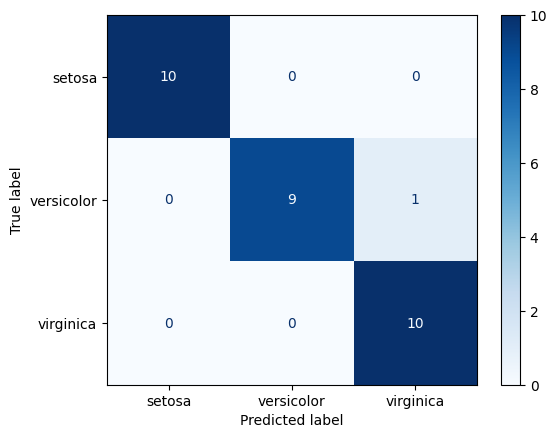

In [18]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=target_names
)

disp.plot(cmap="Blues")
plt.show()

## **Test the Model on New Samples**

Three hand-crafted samples are passed for inference - real-world style usage.

| Sample | Sepal L | Sepal W | Petal L | Petal W | Expected |
|--------|---------|---------|---------|---------|----------|
| 1 | 5.1 | 3.5 | 1.4 | 0.2 | *setosa* |
| 2 | 6.0 | 2.9 | 4.5 | 1.5 | *versicolor* |
| 3 | 6.5 | 3.0 | 5.5 | 1.8 | *virginica* |

These values are drawn from typical measurement ranges for each species in the original Fisher dataset.
`saved_model.predict(sample)` returns integer class indices; `target_names[pred]` maps them back to species names.
The pipeline automatically scales the input before prediction - no manual preprocessing needed.

> ⚠️ **Note:** No independent iris measurement dataset exists online - every source traces back to the same Fisher/Anderson 1936 dataset. These samples are hand-crafted within known species measurement ranges for demonstration purposes only.


In [20]:
import numpy as np

sample = np.array([
        [5.1, 3.5, 1.4, 0.2],   # likely setosa
        [6.0, 2.9, 4.5, 1.5],   # likely versicolor
        [6.5, 3.0, 5.5, 1.8]    # likely virginica
])

predictions = saved_model.predict(sample)

for i, pred in enumerate(predictions):
        print(f"Sample {i + 1}: {target_names[pred]}")

Sample 1: setosa
Sample 2: versicolor
Sample 3: virginica
